M1 AP/R/P/F1

In [4]:
from pathlib import Path
import json
import numpy as np
from collections import Counter
from numpy import trapezoid

CLASS_NAMES = ['person', 'car', 'bicycle', 'othervehicle']
NUM_CLASSES = 4

ROOT = Path('/root/hit-uav')
GT_LABEL_DIR = ROOT / 'labels' / 'test'
IMG_DIR = ROOT / 'images' / 'test'

MODELS = {
    'yolov8n':     ROOT / 'yolov8n_results'     / 'true_predictions' / 'yolov8n_pred.json',
    'yolov8s':     ROOT / 'yolov8s_results'     / 'true_predictions' / 'yolov8s_pred.json',
    'yolov8x':     ROOT / 'yolov8x_results'     / 'true_predictions' / 'yolov8x_pred.json',
    'rtdetr_l':  ROOT / 'rtdetr_l_results'  / 'true_predictions' / 'rtdetr_l_pred.json',
}

IMG_W, IMG_H = 640, 512
IOU_RANGE = np.round(np.arange(0.50, 1.00, 0.05), 2).tolist()


def load_gt(gt_dir):
    gt_by_img = {}
    for txt_file in Path(gt_dir).glob('*.txt'):
        img_id = txt_file.stem
        boxes = []
        with open(txt_file) as f:
            for line in f.readlines():
                line = line.strip()
                if not line:
                    continue
                parts = list(map(float, line.split()))
                cls = int(parts[0])
                _, cx, cy, bw, bh = parts
                x1 = (cx - bw / 2) * IMG_W
                y1 = (cy - bh / 2) * IMG_H
                x2 = (cx + bw / 2) * IMG_W
                y2 = (cy + bh / 2) * IMG_H
                boxes.append([cls, x1, y1, x2, y2])
        gt_by_img[img_id] = boxes
    return gt_by_img


def load_pred(json_path, conf_thres=0.0):
    with open(json_path) as f:
        data = json.load(f)
    pred_by_img = {}
    for k, v in data.items():
        img_id = str(k).strip()
        preds = []
        for d in v:
            cls = int(d[0])
            if cls < 0 or cls >= NUM_CLASSES:
                continue
            conf = float(d[5]) if len(d) > 5 else 1.0
            if conf < conf_thres:
                continue
            preds.append([cls, float(d[1]), float(d[2]), float(d[3]), float(d[4]), conf])
        pred_by_img[img_id] = preds
    return pred_by_img


def calculate_iou(boxA, boxB):
    xA = max(boxA[1], boxB[1])
    yA = max(boxA[2], boxB[2])
    xB = min(boxA[3], boxB[3])
    yB = min(boxA[4], boxB[4])
    interW = max(0, xB - xA)
    interH = max(0, yB - yA)
    interArea = interW * interH
    boxAArea = max(0, boxA[3] - boxA[1]) * max(0, boxA[4] - boxA[2])
    boxBArea = max(0, boxB[3] - boxB[1]) * max(0, boxB[4] - boxB[2])
    denom = boxAArea + boxBArea - interArea
    return interArea / denom if denom > 0 else 0.0


def compute_ap_at_iou(gt_by_img, pred_by_img, iou_thres):
    gt_counts = [0] * NUM_CLASSES
    cls_tp = [0] * NUM_CLASSES
    cls_fn = [0] * NUM_CLASSES
    all_preds_cls = [[] for _ in range(NUM_CLASSES)]

    for img_id, gts in gt_by_img.items():
        preds = pred_by_img.get(img_id, [])
        preds = [p for p in preds if int(p[0]) < NUM_CLASSES]
        preds.sort(key=lambda x: x[5], reverse=True)

        matched_gt = set()
        valid_gts = []
        for gt in gts:
            cls_gt = int(gt[0])
            if cls_gt < 0 or cls_gt >= NUM_CLASSES:
                continue
            valid_gts.append(gt)
            gt_counts[cls_gt] += 1

        for pred in preds:
            cls_p = int(pred[0])
            best_iou, best_idx = 0, -1
            for i, gt in enumerate(valid_gts):
                if i in matched_gt or int(gt[0]) != cls_p:
                    continue
                iou = calculate_iou(pred, gt)
                if iou > best_iou:
                    best_iou = iou
                    best_idx = i

            conf = pred[5]
            if best_iou >= iou_thres and best_idx != -1:
                cls_tp[cls_p] += 1
                matched_gt.add(best_idx)
                all_preds_cls[cls_p].append((conf, 1))
            else:
                all_preds_cls[cls_p].append((conf, 0))

        for i, gt in enumerate(valid_gts):
            if i not in matched_gt:
                cls_fn[int(gt[0])] += 1

    aps = []
    all_rc = []
    all_pr = []
    for c in range(NUM_CLASSES):
        preds_c = all_preds_cls[c]
        if len(preds_c) == 0:
            aps.append(0.0)
            all_rc.append([0.0])
            all_pr.append([1.0])
            continue
        preds_c.sort(key=lambda x: x[0], reverse=True)
        tp_cum = np.cumsum([p[1] for p in preds_c])
        fp_cum = np.cumsum([1 - p[1] for p in preds_c])
        rc = tp_cum / (gt_counts[c] + 1e-6)
        pr = tp_cum / (tp_cum + fp_cum + 1e-6)
        rc_curve = np.concatenate([[0], rc, [1]])
        pr_curve = np.concatenate([[1], pr, [0]])
        pr_curve = np.maximum.accumulate(pr_curve[::-1])[::-1]
        all_rc.append(rc_curve.tolist())
        all_pr.append(pr_curve.tolist())
        aps.append(float(trapezoid(pr_curve, rc_curve)))

    tp_total = sum(cls_tp)
    fn_total = sum(cls_fn)
    fp_total = sum(len(all_preds_cls[c]) - cls_tp[c] for c in range(NUM_CLASSES))

    all_preds_flat = []
    for c in range(NUM_CLASSES):
        all_preds_flat.extend(all_preds_cls[c])
    if len(all_preds_flat) > 0:
        all_preds_flat.sort(key=lambda x: x[0], reverse=True)
        tp_all = np.cumsum([p[1] for p in all_preds_flat])
        fp_all = np.cumsum([1 - p[1] for p in all_preds_flat])
        gt_all = sum(gt_counts)
        rc_overall = np.concatenate([[0], tp_all / (gt_all + 1e-6), [1]])
        pr_overall = np.concatenate([[1], tp_all / (tp_all + fp_all + 1e-6), [0]])
    else:
        rc_overall = np.array([0, 1])
        pr_overall = np.array([1, 0])

    return (aps, gt_counts, cls_tp, cls_fn, tp_total, fp_total, fn_total,
            all_rc, all_pr, rc_overall.tolist(), pr_overall.tolist())


def evaluate_model(gt_by_img, pred_by_img, iou_range=None):
    if iou_range is None:
        iou_range = [0.5]

    (aps50, gt_counts, cls_tp, cls_fn, tp, fp, fn,
     all_rc, all_pr, rc_overall, pr_overall) = compute_ap_at_iou(
        gt_by_img, pred_by_img, 0.5)

    all_aps = []
    for t in iou_range:
        aps_t, _, _, _, _, _, _, _, _, _, _ = compute_ap_at_iou(
            gt_by_img, pred_by_img, t)
        all_aps.append(aps_t)

    mAP50 = float(np.mean(aps50))
    mAP50_95 = float(np.mean([np.mean(a) for a in all_aps]))

    return {
        'mAP50': mAP50,
        'mAP50_95': mAP50_95,
        'class_AP': aps50,
        'gt_counts': gt_counts,
        'cls_tp': cls_tp,
        'cls_fn': cls_fn,
        'TP': tp, 'FP': fp, 'FN': fn,
        'pr_curves': {
            'overall': {'rc': rc_overall, 'pr': pr_overall},
            'per_class': [{'rc': all_rc[c], 'pr': all_pr[c]} for c in range(NUM_CLASSES)]
        }
    }



print("=== 加载 GT ===")
gt_data = load_gt(GT_LABEL_DIR)
print(f"GT 图片数: {len(gt_data)}")
print(f"GT 总框数: {sum(len(v) for v in gt_data.values())}")

pred_data_all = {}
pred_data_report = {}
for name, path in MODELS.items():
    if not Path(path).exists():
        print(f"!!! 缺少预测文件: {path}")
        continue
    pred_data_all[name] = load_pred(path, conf_thres=0.001)
    pred_data_report[name] = load_pred(path, conf_thres=0.05)
    print(f"{name}: 预测已加载 (0.001: {sum(len(v) for v in pred_data_all[name].values())} 框, "
          f"0.05: {sum(len(v) for v in pred_data_report[name].values())} 框)")

# ---------- 计算 AP ----------
summary_ap = {}
for name in MODELS:
    if name not in pred_data_all:
        continue
    res = evaluate_model(gt_data, pred_data_all[name], iou_range=IOU_RANGE)
    summary_ap[name] = res
    print(f"\n{name}: mAP@0.5={res['mAP50']:.4f}, mAP@.5:.95={res['mAP50_95']:.4f}")

# ---------- AP汇总表 ----------
print("\n===== AP 汇总表 (conf≥0.001) =====")
print(f"{'模型':<14}{'mAP@0.5':<10}{'mAP@.5:.95':<12}" + "".join(f"{c:<13}" for c in CLASS_NAMES))
for name, r in summary_ap.items():
    ap_str = " ".join(f"{x:.4f}      " for x in r['class_AP'])
    print(f"{name:<14}{r['mAP50']:<10.4f}{r['mAP50_95']:<12.4f}{ap_str}")

# ---------- 统计 conf≥0.05 的预测类别分布 ----------
pred_cls_counter_report = {}
for name, pred_dict in pred_data_report.items():
    counter = Counter()
    for img_id, preds in pred_dict.items():
        for p in preds:
            counter[int(p[0])] += 1
    pred_cls_counter_report[name] = counter

# ---------- 计算 P/R/F1 ----------
summary_report = {}
for name in pred_data_report:
    res = evaluate_model(gt_data, pred_data_report[name], iou_range=[0.5])

    tp, fp, fn = res['TP'], res['FP'], res['FN']
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0

    cls_prec, cls_rec, cls_f1 = [], [], []
    cls_counter = pred_cls_counter_report[name]
    for c in range(NUM_CLASSES):
        ctp = res['cls_tp'][c]
        cfn = res['cls_fn'][c]
        gtc = res['gt_counts'][c]
        cfp = cls_counter.get(c, 0) - ctp
        p_c = ctp / (ctp + cfp) if (ctp + cfp) > 0 else 0
        r_c = ctp / gtc if gtc > 0 else 0
        f1_c = 2 * p_c * r_c / (p_c + r_c) if (p_c + r_c) > 0 else 0
        cls_prec.append(round(p_c, 4))
        cls_rec.append(round(r_c, 4))
        cls_f1.append(round(f1_c, 4))

    summary_report[name] = {
        'total_boxes': sum(cls_counter.values()),
        'TP': tp, 'FP': fp, 'FN': fn,
        'precision': precision, 'recall': recall, 'f1': f1,
        'cls_tp': res['cls_tp'],
        'cls_precision': cls_prec,
        'cls_recall': cls_rec,
        'cls_f1': cls_f1,
        'pred_cls_dist': {int(k): int(v) for k, v in cls_counter.items()},
    }

# ---------- 打印 P/R/F1 汇总表 ----------
print("\n===== P/R/F1 汇总表 (conf≥0.05, IoU=0.5) =====")
header = f"{'模型':<14}{'总框数':<9}{'P':<9}{'R':<9}{'F1':<9}{'TP':<7}{'FP':<7}{'FN':<7}"
print(header)
print("-" * 70)
for name, r in summary_report.items():
    print(f"{name:<14}{r['total_boxes']:<9}{r['precision']:<9.4f}{r['recall']:<9.4f}"
          f"{r['f1']:<9.4f}{r['TP']:<7}{r['FP']:<7}{r['FN']:<7}")

print("\n【各类别 Recall】")
print(f"{'模型':<14}" + "".join(f"{c:<14}" for c in CLASS_NAMES))
for name, r in summary_report.items():
    print(f"{name:<14}" + "".join(f"{x:<14.4f}" for x in r['cls_recall']))

print("\n【各类别 Precision】")
print(f"{'模型':<14}" + "".join(f"{c:<14}" for c in CLASS_NAMES))
for name, r in summary_report.items():
    print(f"{name:<14}" + "".join(f"{x:<14.4f}" for x in r['cls_precision']))

# ---------- 合并保存 ----------
final_summary = {
    'ap': summary_ap,
    'prf': summary_report,
}
save_path = ROOT / 'evaluate_results' / 'M1_summary.json'
with open(save_path, 'w') as f:
    json.dump(final_summary, f, indent=2, ensure_ascii=False)
print(f"\n✅ 结果已保存至: {save_path}")

=== 加载 GT ===
GT 图片数: 571
GT 总框数: 4811
yolov8n: 预测已加载 (0.001: 8317 框, 0.05: 5548 框)
yolov8s: 预测已加载 (0.001: 11367 框, 0.05: 6078 框)
yolov8x: 预测已加载 (0.001: 6597 框, 0.05: 5052 框)
rtdetr_r50: 预测已加载 (0.001: 171300 框, 0.05: 5817 框)

yolov8n: mAP@0.5=0.7812, mAP@.5:.95=0.5046

yolov8s: mAP@0.5=0.8007, mAP@.5:.95=0.5131

yolov8x: mAP@0.5=0.7906, mAP@.5:.95=0.5325

rtdetr_r50: mAP@0.5=0.8133, mAP@.5:.95=0.5267

===== AP 汇总表 (conf≥0.001) =====
模型            mAP@0.5   mAP@.5:.95  person       car          bicycle      othervehicle 
yolov8n       0.7812    0.5046      0.8666       0.9458       0.8588       0.4537      
yolov8s       0.8007    0.5131      0.8690       0.9489       0.8678       0.5172      
yolov8x       0.7906    0.5325      0.8770       0.9414       0.8616       0.4826      
rtdetr_r50    0.8133    0.5267      0.9014       0.9534       0.8812       0.5173      

===== P/R/F1 汇总表 (conf≥0.05, IoU=0.5) =====
模型            总框数      P        R        F1       TP     FP     FN     
-----

M2 置信度-性能敏感矩阵

=== 加载 GT ===
GT 图片数: 571, 总框数: 4811

处理模型: yolov8n
  conf=0.05: P=0.7558, R=0.8772, F1=0.8120, TP=4193, FP=1355, FN=587, 过滤后框数=5548
  conf=0.10: P=0.7905, R=0.8701, F1=0.8284, TP=4159, FP=1102, FN=621, 过滤后框数=5261
  conf=0.15: P=0.8112, R=0.8630, F1=0.8363, TP=4125, FP=960, FN=655, 过滤后框数=5085
  conf=0.25: P=0.8392, R=0.8536, F1=0.8463, TP=4080, FP=782, FN=700, 过滤后框数=4862
  conf=0.50: P=0.8834, R=0.8276, F1=0.8546, TP=3956, FP=522, FN=824, 过滤后框数=4478

处理模型: yolov8s
  conf=0.05: P=0.7006, R=0.8908, F1=0.7843, TP=4258, FP=1820, FN=522, 过滤后框数=6078
  conf=0.10: P=0.7541, R=0.8772, F1=0.8110, TP=4193, FP=1367, FN=587, 过滤后框数=5560
  conf=0.15: P=0.7903, R=0.8697, F1=0.8281, TP=4157, FP=1103, FN=623, 过滤后框数=5260
  conf=0.25: P=0.8348, R=0.8523, F1=0.8435, TP=4074, FP=806, FN=706, 过滤后框数=4880
  conf=0.50: P=0.9032, R=0.8063, F1=0.8520, TP=3854, FP=413, FN=926, 过滤后框数=4267

处理模型: yolov8x
  conf=0.05: P=0.8118, R=0.8579, F1=0.8342, TP=4101, FP=951, FN=679, 过滤后框数=5052
  conf=0.10: P=0.8343, R=0.8481, 

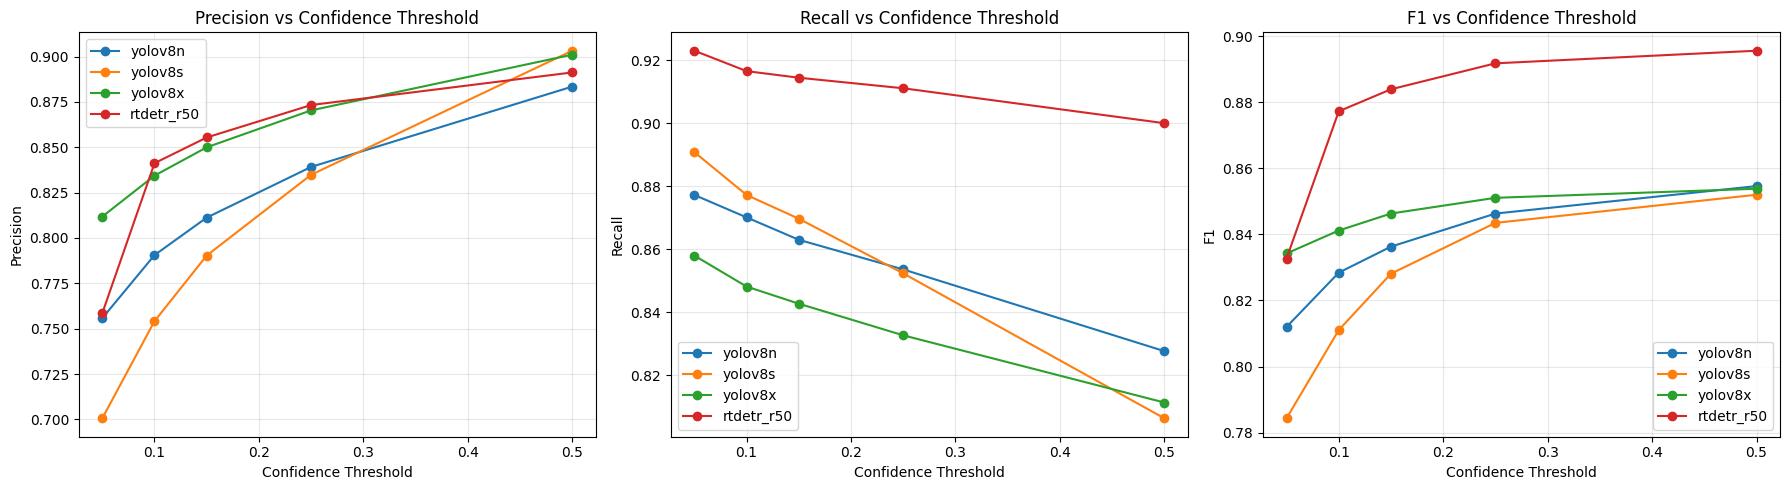

In [5]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt

CLASS_NAMES = ['person', 'car', 'bicycle', 'othervehicle']
NUM_CLASSES = 4

ROOT = Path('/root/hit-uav')
GT_LABEL_DIR = ROOT / 'labels' / 'test'
IMG_DIR = ROOT / 'images' / 'test'

MODELS = {
    'yolov8n':     ROOT / 'yolov8n_results'     / 'true_predictions' / 'yolov8n_pred.json',
    'yolov8s':     ROOT / 'yolov8s_results'     / 'true_predictions' / 'yolov8s_pred.json',
    'yolov8x':     ROOT / 'yolov8x_results'     / 'true_predictions' / 'yolov8x_pred.json',
    'rtdetr_l':  ROOT / 'rtdetr_l_results'  / 'true_predictions' / 'rtdetr_l_pred.json',
}

CONF_LIST = [0.05, 0.1, 0.15, 0.25, 0.5]
IMG_W, IMG_H = 640, 512

# ============ 数据加载 ============
def load_gt(gt_dir):
    """加载 GT：{img_id: [[cls, x1, y1, x2, y2], ...]} (绝对坐标)"""
    gt_by_img = {}
    for txt_file in Path(gt_dir).glob('*.txt'):
        img_id = txt_file.stem
        boxes = []
        with open(txt_file) as f:
            for line in f.readlines():
                line = line.strip()
                if not line:
                    continue
                parts = list(map(float, line.split()))
                cls = int(parts[0])
                _, cx, cy, bw, bh = parts
                x1 = (cx - bw / 2) * IMG_W
                y1 = (cy - bh / 2) * IMG_H
                x2 = (cx + bw / 2) * IMG_W
                y2 = (cy + bh / 2) * IMG_H
                boxes.append([cls, x1, y1, x2, y2])
        gt_by_img[img_id] = boxes
    return gt_by_img


def load_pred(json_path, conf_thres=0.0):
    """加载预测：{img_id: [[cls, x1, y1, x2, y2, conf], ...]}"""
    with open(json_path) as f:
        data = json.load(f)
    pred_by_img = {}
    for k, v in data.items():
        img_id = str(k).strip()
        preds = []
        for d in v:
            cls = int(d[0])
            if cls < 0 or cls >= NUM_CLASSES:
                continue
            conf = float(d[5]) if len(d) > 5 else 1.0
            if conf < conf_thres:
                continue
            preds.append([cls, float(d[1]), float(d[2]), float(d[3]), float(d[4]), conf])
        pred_by_img[img_id] = preds
    return pred_by_img


def calculate_iou(boxA, boxB):
    xA = max(boxA[1], boxB[1])
    yA = max(boxA[2], boxB[2])
    xB = min(boxA[3], boxB[3])
    yB = min(boxA[4], boxB[4])
    interW = max(0, xB - xA)
    interH = max(0, yB - yA)
    interArea = interW * interH
    boxAArea = max(0, boxA[3] - boxA[1]) * max(0, boxA[4] - boxA[2])
    boxBArea = max(0, boxB[3] - boxB[1]) * max(0, boxB[4] - boxB[2])
    denom = boxAArea + boxBArea - interArea
    return interArea / denom if denom > 0 else 0.0


def match_at_iou(gt_by_img, pred_by_img, iou_thres):
    """复用 M1 的贪心匹配逻辑，返回某个 IoU 下的 TP/FP/FN"""
    gt_counts = [0] * NUM_CLASSES
    cls_tp = [0] * NUM_CLASSES
    cls_fn = [0] * NUM_CLASSES
    all_preds_cls = [[] for _ in range(NUM_CLASSES)]

    for img_id, gts in gt_by_img.items():
        preds = pred_by_img.get(img_id, [])
        preds = [p for p in preds if int(p[0]) < NUM_CLASSES]
        preds.sort(key=lambda x: x[5], reverse=True)

        matched_gt = set()
        valid_gts = []
        for gt in gts:
            cls_gt = int(gt[0])
            if cls_gt < 0 or cls_gt >= NUM_CLASSES:
                continue
            valid_gts.append(gt)
            gt_counts[cls_gt] += 1

        for pred in preds:
            cls_p = int(pred[0])
            best_iou, best_idx = 0, -1
            for i, gt in enumerate(valid_gts):
                if i in matched_gt or int(gt[0]) != cls_p:
                    continue
                iou = calculate_iou(pred, gt)
                if iou > best_iou:
                    best_iou = iou
                    best_idx = i

            if best_iou >= iou_thres and best_idx != -1:
                cls_tp[cls_p] += 1
                matched_gt.add(best_idx)
                all_preds_cls[cls_p].append((pred[5], 1))
            else:
                all_preds_cls[cls_p].append((pred[5], 0))

        for i, gt in enumerate(valid_gts):
            if i not in matched_gt:
                cls_fn[int(gt[0])] += 1

    tp_total = sum(cls_tp)
    fn_total = sum(cls_fn)
    fp_total = sum(len(all_preds_cls[c]) - cls_tp[c] for c in range(NUM_CLASSES))

    return gt_counts, cls_tp, cls_fn, tp_total, fp_total, fn_total


# ============ 主流程 ============
if __name__ == "__main__":
    print("=== 加载 GT ===")
    gt_data = load_gt(GT_LABEL_DIR)
    print(f"GT 图片数: {len(gt_data)}, 总框数: {sum(len(v) for v in gt_data.values())}")

    results = {model: {} for model in MODELS}

    for model_name, json_path in MODELS.items():
        if not Path(json_path).exists():
            print(f"\n!!! {model_name} 预测文件不存在: {json_path}")
            continue

        print(f"\n{'='*60}")
        print(f"处理模型: {model_name}")
        print(f"{'='*60}")

        for conf in CONF_LIST:
            pred_data = load_pred(json_path, conf_thres=conf)
            boxes_after_filter = sum(len(v) for v in pred_data.values())

            # 取 IoU=0.5 下的 TP/FP/FN
            _, _, _, tp, fp, fn = match_at_iou(gt_data, pred_data, 0.5)

            precision = tp / (tp + fp) if (tp + fp) > 0 else 0
            recall = tp / (tp + fn) if (tp + fn) > 0 else 0
            f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0

            print(f"  conf={conf:.2f}: P={precision:.4f}, R={recall:.4f}, F1={f1:.4f}, "
                  f"TP={tp}, FP={fp}, FN={fn}, 过滤后框数={boxes_after_filter}")

            results[model_name][str(conf)] = {
                'conf': conf,
                'Precision': round(precision, 6),
                'Recall': round(recall, 6),
                'F1': round(f1, 6),
                'TP': int(tp),
                'FP': int(fp),
                'FN': int(fn),
                'boxes_after_filter': int(boxes_after_filter),
            }

    # ============ 保存 JSON ============
    save_path = ROOT / 'M2_conf_sensitivity.json'
    with open(save_path, 'w') as f:
        json.dump(results, f, indent=2, ensure_ascii=False)
    print(f"\n✅ 结果已保存: {save_path}")

    # ============ 打印横向表格 ============
    print("\n\n" + "=" * 100)
    print("M2 置信度-性能敏感矩阵 · 横向对比表")
    print("=" * 100)

    for model_name in MODELS:
        if model_name not in results or not results[model_name]:
            continue
        print(f"\n--- {model_name} ---")
        header = f"{'Conf':<8}{'框数':<10}{'Precision':<12}{'Recall':<12}{'F1':<12}{'TP':<8}{'FP':<8}{'FN':<8}"
        print(header)
        print("-" * 75)
        for conf_str in sorted(results[model_name].keys(), key=lambda x: float(x)):
            r = results[model_name][conf_str]
            print(f"{r['conf']:<8.2f}{r['boxes_after_filter']:<10}{r['Precision']:<12.4f}{r['Recall']:<12.4f}"
                  f"{r['F1']:<12.4f}{r['TP']:<8}{r['FP']:<8}{r['FN']:<8}")

    # ============ 绘制折线图 ============
    plt.rcParams['font.sans-serif'] = ['SimHei', 'DejaVu Sans']
    plt.rcParams['axes.unicode_minus'] = False

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    for ax, metric in zip(axes, ['Precision', 'Recall', 'F1']):
        for model_name in MODELS:
            if model_name not in results or not results[model_name]:
                continue
            confs = sorted([float(c) for c in results[model_name].keys()])
            vals = [results[model_name][str(c)][metric] for c in confs]
            ax.plot(confs, vals, marker='o', label=model_name)
        ax.set_xlabel('Confidence Threshold')
        ax.set_ylabel(metric)
        ax.set_title(f'{metric} vs Confidence Threshold')
        ax.grid(True, alpha=0.3)
        ax.legend()

    plt.tight_layout()
    plot_path = ROOT / 'M2_conf_sensitivity.png'
    plt.savefig(plot_path, dpi=200, bbox_inches='tight')
    print(f"\n✅ 折线图已保存: {plot_path}")
    plt.show()

M3目标尺寸-性能矩阵

=== 加载 GT ===
GT 图片数: 571
全局 GT 尺寸分布: {'S': 3378, 'M': 1333, 'L': 69}

=== 处理模型: yolov8n ===

[S] mAP@0.5: 0.5466, mAP@.5:.95: 0.2958
  P: 0.4699, R: 0.8697, F1: 0.6101
  TP=2938, FP=3315, FN=440
  各类 AP@0.5: {'person': '0.8648', 'car': '0.7206', 'bicycle': '0.6009', 'othervehicle': '0.0000'}
  [person S] R=0.9063, P=0.4994, fitness=1.0561

[M] mAP@0.5: 0.6300, mAP@.5:.95: 0.4665
  P: 0.6295, R: 0.9242, F1: 0.7489
  TP=1232, FP=725, FN=101
  各类 AP@0.5: {'person': '0.2653', 'car': '0.9222', 'bicycle': '0.9097', 'othervehicle': '0.4228'}
  [person S] R=0.2500, P=0.0408, fitness=0.2622

[L] mAP@0.5: 0.3649, mAP@.5:.95: 0.3006
  P: 0.5888, R: 0.9130, F1: 0.7159
  TP=63, FP=44, FN=6
  各类 AP@0.5: {'person': '0.0000', 'car': '0.9239', 'bicycle': '0.0000', 'othervehicle': '0.5357'}
  [person S] R=0.0000, P=0.0000, fitness=0.0000

=== 处理模型: yolov8s ===

[S] mAP@0.5: 0.6026, mAP@.5:.95: 0.3375
  P: 0.3428, R: 0.9005, F1: 0.4965
  TP=3042, FP=5833, FN=336
  各类 AP@0.5: {'person': '0.8673', 'car': 

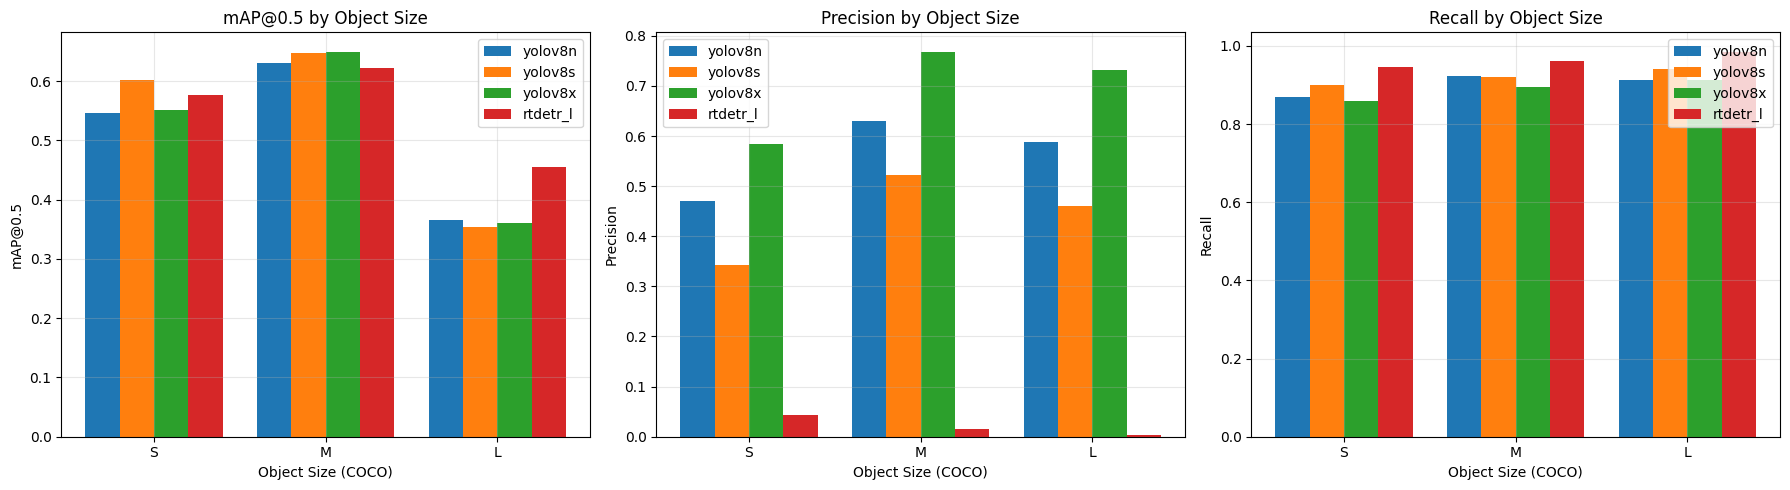

✅ 热力图已保存: /root/hit-uav/evaluate_results/M3_class_AP_heatmap.png


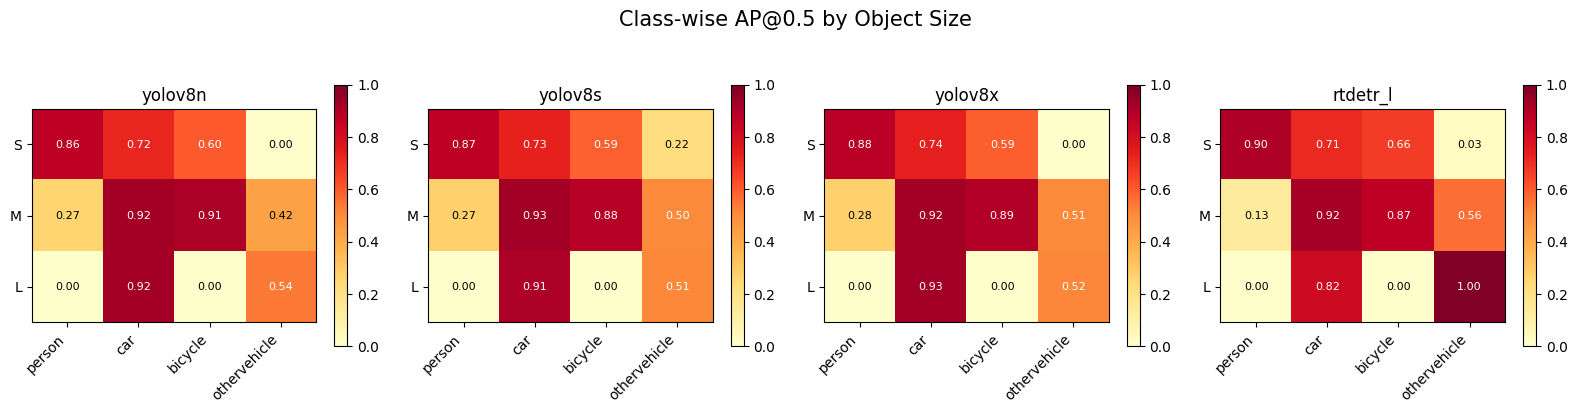



M3 尺寸分级汇总表
模型          尺寸    mAP@0.5   mAP@.5:.95  P       R       F1      TP     FP     FN     GT总数    
------------------------------------------------------------------------------------------------------------------------
yolov8n     S     0.5466    0.2958      0.4699  0.8697  0.6101  2938   3315   440    3378    
yolov8n     M     0.6300    0.4665      0.6295  0.9242  0.7489  1232   725    101    1333    
yolov8n     L     0.3649    0.3006      0.5888  0.9130  0.7159  63     44     6      69      
yolov8s     S     0.6026    0.3375      0.3428  0.9005  0.4965  3042   5833   336    3378    
yolov8s     M     0.6476    0.4675      0.5215  0.9197  0.6656  1226   1125   107    1333    
yolov8s     L     0.3546    0.2909      0.4610  0.9420  0.6190  65     76     4      69      
yolov8x     S     0.5514    0.3257      0.5843  0.8579  0.6951  2898   2062   480    3378    
yolov8x     M     0.6498    0.4965      0.7685  0.8942  0.8266  1192   359    141    1333    
yolov8x     L     0.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path('/root/hit-uav')
CLASS_NAMES = ['person', 'car', 'bicycle', 'othervehicle']
NUM_CLASSES = len(CLASS_NAMES)

MODELS = {
    'yolov8n':     ROOT / 'yolov8n_results'    / 'true_predictions' / 'yolov8n_pred.json',
    'yolov8s':     ROOT / 'yolov8s_results'    / 'true_predictions' / 'yolov8s_pred.json',
    'yolov8x':     ROOT / 'yolov8x_results'    / 'true_predictions' / 'yolov8x_pred.json',
    'rtdetr_l':  ROOT / 'rtdetr_l_results' / 'true_predictions' / 'rtdetr_l_pred.json',
}

GT_LABEL_DIR = ROOT / 'labels' / 'test'
IMG_W, IMG_H = 640, 512

# COCO 标准尺寸分级（像素面积）
AREA_THRES = [(0, 32**2, 'S'), (32**2, 96**2, 'M'), (96**2, float('inf'), 'L')]

CONF_THRES = 0.001

# 用于 mAP@.5:.95 的 IoU 阈值序列
IOU_THRES_LIST = [round(0.5 + 0.05 * i, 2) for i in range(10)]

plt.rcParams['font.sans-serif'] = ['SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False


# ============ 数据加载 ============
def load_gt(gt_dir):
    """加载 GT：{img_id: [[cls, x1, y1, x2, y2], ...]} (绝对坐标)"""
    gt_by_img = {}
    for txt_file in Path(gt_dir).glob('*.txt'):
        img_id = txt_file.stem
        boxes = []
        with open(txt_file) as f:
            for line in f.readlines():
                line = line.strip()
                if not line:
                    continue
                parts = list(map(float, line.split()))
                cls = int(parts[0])
                if cls >= NUM_CLASSES:
                    continue
                _, cx, cy, bw, bh = parts
                x1 = (cx - bw / 2) * IMG_W
                y1 = (cy - bh / 2) * IMG_H
                x2 = (cx + bw / 2) * IMG_W
                y2 = (cy + bh / 2) * IMG_H
                boxes.append([cls, x1, y1, x2, y2])
        gt_by_img[img_id] = boxes
    return gt_by_img


def load_pred(json_path, conf_thres=0.0):
    """加载预测：{img_id: [[cls, x1, y1, x2, y2, conf], ...]}，可选按置信度过滤"""
    with open(json_path) as f:
        data = json.load(f)
    pred_by_img = {}
    for k, v in data.items():
        img_id = str(k).strip()
        preds = []
        for d in v:
            cls = int(d[0])
            if cls >= NUM_CLASSES:
                continue
            conf = float(d[5]) if len(d) > 5 else 1.0
            if conf < conf_thres:
                continue
            preds.append([cls, float(d[1]), float(d[2]), float(d[3]), float(d[4]), conf])
        pred_by_img[img_id] = preds
    return pred_by_img


def calculate_iou(boxA, boxB):
    xA = max(boxA[1], boxB[1])
    yA = max(boxA[2], boxB[2])
    xB = min(boxA[3], boxB[3])
    yB = min(boxA[4], boxB[4])
    interW = max(0, xB - xA)
    interH = max(0, yB - yA)
    interArea = interW * interH
    boxAArea = max(0, boxA[3] - boxA[1]) * max(0, boxA[4] - boxA[2])
    boxBArea = max(0, boxB[3] - boxB[1]) * max(0, boxB[4] - boxB[2])
    denom = boxAArea + boxBArea - interArea
    return interArea / denom if denom > 0 else 0.0


# ============ 核心评估函数 ============
def compute_ap_at_iou_size(gt_by_img, pred_by_img, iou_thres, size_bucket):
    """
    在单个 IoU 阈值、单个尺寸分桶下，计算各类 AP、TP/FP/FN。
    预测框和 GT 框的尺寸均按当前分桶过滤。
    新增返回 fp_by_cls，用于计算 S 类 person 单独指标。
    """
    min_area, max_area = size_bucket
    gt_counts = [0] * NUM_CLASSES
    cls_tp = [0] * NUM_CLASSES
    cls_fn = [0] * NUM_CLASSES
    all_preds_cls = [[] for _ in range(NUM_CLASSES)]

    for img_id, gts in gt_by_img.items():
        # 1. 过滤当前尺寸分桶的 GT
        valid_gts = []
        for gt in gts:
            cls_gt = int(gt[0])
            if cls_gt >= NUM_CLASSES:
                continue
            w = gt[3] - gt[1]
            h = gt[4] - gt[2]
            area = w * h
            if min_area <= area < max_area:
                valid_gts.append(gt)
                gt_counts[cls_gt] += 1

        # 2. 过滤当前尺寸分桶的预测框
        preds_raw = pred_by_img.get(img_id, [])
        preds = []
        for p in preds_raw:
            if int(p[0]) >= NUM_CLASSES:
                continue
            p_area = (p[3] - p[1]) * (p[4] - p[2])
            if min_area <= p_area < max_area:
                preds.append(p)

        # 按置信度降序
        preds.sort(key=lambda x: x[5], reverse=True)

        # 3. 贪心匹配
        matched_gt = set()
        for pred in preds:
            cls_p = int(pred[0])
            best_iou, best_idx = 0, -1
            for i, gt in enumerate(valid_gts):
                if i in matched_gt or int(gt[0]) != cls_p:
                    continue
                iou = calculate_iou(pred, gt)
                if iou > best_iou:
                    best_iou = iou
                    best_idx = i

            conf = pred[5]
            if best_iou >= iou_thres and best_idx != -1:
                cls_tp[cls_p] += 1
                matched_gt.add(best_idx)
                all_preds_cls[cls_p].append((conf, 1))
            else:
                all_preds_cls[cls_p].append((conf, 0))

        for i, gt in enumerate(valid_gts):
            if i not in matched_gt:
                cls_fn[int(gt[0])] += 1

    # 新增：预测框按类别统计 FP = 该类别预测总数 - TP
    fp_by_cls = [len(all_preds_cls[c]) - cls_tp[c] for c in range(NUM_CLASSES)]

    # 4. 计算各类 AP（使用单调包络 + 梯形积分）
    aps = []
    for c in range(NUM_CLASSES):
        preds_c = all_preds_cls[c]
        if len(preds_c) == 0:
            aps.append(0.0)
            continue
        preds_c.sort(key=lambda x: x[0], reverse=True)
        tp_cum = np.cumsum([p[1] for p in preds_c])
        fp_cum = np.cumsum([1 - p[1] for p in preds_c])
        rc = tp_cum / (gt_counts[c] + 1e-6)
        pr = tp_cum / (tp_cum + fp_cum + 1e-6)

        # 单调包络：保证 PR 曲线下面积正确
        pr_curve = np.concatenate([[1], pr, [0]])
        rc_curve = np.concatenate([[0], rc, [1]])
        for i in range(len(pr_curve) - 1, 0, -1):
            pr_curve[i - 1] = max(pr_curve[i - 1], pr_curve[i])
        aps.append(float(np.trapezoid(pr_curve, rc_curve)))

    # 5. 整体统计量
    tp_total = sum(cls_tp)
    fn_total = sum(cls_fn)
    fp_total = sum(fp_by_cls)

    return aps, gt_counts, cls_tp, cls_fn, fp_by_cls, tp_total, fp_total, fn_total


def compute_mAP_at_iou_size(gt_data, pred_data, iou_thres_list, size_bucket):
    """计算给定尺寸分桶下的 mAP@IoU list 的均值（常用于 mAP@.5:.95）"""
    mAP_list = []
    for iou in iou_thres_list:
        aps, *_ = compute_ap_at_iou_size(gt_data, pred_data, iou, size_bucket)
        mAP_list.append(float(np.mean(aps)))
    return float(np.mean(mAP_list))


# ============ 主流程 ============
if __name__ == "__main__":
    print("=== 加载 GT ===")
    gt_data = load_gt(GT_LABEL_DIR)
    print(f"GT 图片数: {len(gt_data)}")

    # 统计全局 GT 尺寸分布
    size_gt_counts = {size: 0 for _, _, size in AREA_THRES}
    for img_id, gts in gt_data.items():
        for gt in gts:
            w = gt[3] - gt[1]
            h = gt[4] - gt[2]
            area = w * h
            for min_a, max_a, size in AREA_THRES:
                if min_a <= area < max_a:
                    size_gt_counts[size] += 1
                    break
    print(f"全局 GT 尺寸分布: {size_gt_counts}")

    # 存储结果
    results = {}

    for model_name, json_path in MODELS.items():
        if not Path(json_path).exists():
            print(f"\n!!! 跳过 {model_name}: 文件不存在 {json_path}")
            continue

        print(f"\n{'='*60}")
        print(f"=== 处理模型: {model_name} ===")
        print(f"{'='*60}")

        pred_data = load_pred(json_path, conf_thres=CONF_THRES)
        model_results = {}

        for min_area, max_area, size in AREA_THRES:
            size_bucket = (min_area, max_area)

            # IoU=0.5 下的 AP、P/R/F1
            aps_50, gt_counts, cls_tp, cls_fn, fp_by_cls, tp, fp, fn = compute_ap_at_iou_size(
                gt_data, pred_data, 0.5, size_bucket)
            mAP_50 = float(np.mean(aps_50))

            precision = tp / (tp + fp) if (tp + fp) > 0 else 0
            recall = tp / (tp + fn) if (tp + fn) > 0 else 0
            f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0

            # S 类 person 单独统计（person_idx = 0）
            person_idx = 0
            person_gt = gt_counts[person_idx]
            person_tp = cls_tp[person_idx]
            person_fp = fp_by_cls[person_idx]

            person_recall = person_tp / person_gt if person_gt > 0 else 0
            person_precision = person_tp / (person_tp + person_fp) if (person_tp + person_fp) > 0 else 0
            person_fitness = person_recall + 0.3 * person_precision

            # mAP@.5:.95
            mAP_strict = compute_mAP_at_iou_size(
                gt_data, pred_data, IOU_THRES_LIST, size_bucket)

            model_results[size] = {
                'mAP_50': mAP_50,
                'mAP_50_95': mAP_strict,
                'precision': precision,
                'recall': recall,
                'f1': f1,
                'TP': tp, 'FP': fp, 'FN': fn,
                'gt_counts': gt_counts,
                'class_AP_50': aps_50,
                'person_recall': person_recall,
                'person_precision': person_precision,
                'person_fitness': person_fitness,
                'cls_tp': cls_tp,
                'cls_fp': fp_by_cls,
            }

            print(f"\n[{size}] mAP@0.5: {mAP_50:.4f}, mAP@.5:.95: {mAP_strict:.4f}")
            print(f"  P: {precision:.4f}, R: {recall:.4f}, F1: {f1:.4f}")
            print(f"  TP={tp}, FP={fp}, FN={fn}")
            print(f"  各类 AP@0.5: {dict(zip(CLASS_NAMES, [f'{x:.4f}' for x in aps_50]))}")
            print(f"  [person S] R={person_recall:.4f}, P={person_precision:.4f}, fitness={person_fitness:.4f}")

        results[model_name] = model_results

    # ============ 保存 JSON ============
    save_path = ROOT / 'evaluate_results' / 'M3_size_summary.json'
    save_path.parent.mkdir(parents=True, exist_ok=True)
    with open(save_path, 'w') as f:
        json.dump(results, f, indent=2, ensure_ascii=False)
    print(f"\n✅ 结果已保存至: {save_path}")

    # ============ 打印 S类 person baseline 小表 ============
    print("\n\n" + "=" * 100)
    print("Baseline：S类 person Recall@IoU=0.5（测试集，conf>=0.001）")
    print("=" * 100)
    header = (f"{'模型':<12}{'S类person Recall':<20}{'S类person Precision':<24}"
              f"{'Fitness':<12}{'S类GT数':<10}")
    print(header)
    print("-" * 100)

    for model_name, model_results in results.items():
        s_metrics = model_results['S']
        print(f"{model_name:<12}{s_metrics['person_recall']:<20.6f}"
              f"{s_metrics['person_precision']:<24.6f}"
              f"{s_metrics['person_fitness']:<12.6f}"
              f"{s_metrics['gt_counts'][0]:<10}")

    print("=" * 100)

    # ============ 绘图 1：S/M/L 的 mAP/P/R 总览面板 ============
    sizes = ['S', 'M', 'L']
    x = np.arange(len(sizes))
    width = 0.2
    metrics = [('mAP@0.5', 'mAP_50'), ('Precision', 'precision'), ('Recall', 'recall')]

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    for ax, (title, key) in zip(axes, metrics):
        for i, (model_name, model_results) in enumerate(results.items()):
            vals = [model_results[size][key] for size in sizes]
            ax.bar(x + i * width, vals, width, label=model_name)
        ax.set_xlabel('Object Size (COCO)')
        ax.set_ylabel(title)
        ax.set_title(f'{title} by Object Size')
        ax.set_xticks(x + width * 1.5)
        ax.set_xticklabels(sizes)
        ax.legend()
        ax.grid(True, alpha=0.3)

    plt.tight_layout()
    panel_path = ROOT / 'evaluate_results' / 'M3_size_panel.png'
    plt.savefig(panel_path, dpi=200, bbox_inches='tight')
    print(f"✅ 面板图已保存: {panel_path}")
    plt.show()

    # ============ 绘图 2：各类别 AP@0.5 热力图（S/M/L × 类别） ============
    fig, axes = plt.subplots(1, len(results), figsize=(4 * len(results), 4), squeeze=False)

    for ax, (model_name, model_results) in zip(axes[0], results.items()):
        heat_data = np.zeros((len(sizes), NUM_CLASSES))
        for i, size in enumerate(sizes):
            heat_data[i] = model_results[size]['class_AP_50']
        im = ax.imshow(heat_data, cmap='YlOrRd', vmin=0, vmax=1)
        ax.set_xticks(range(NUM_CLASSES))
        ax.set_xticklabels(CLASS_NAMES, rotation=45, ha='right')
        ax.set_yticks(range(len(sizes)))
        ax.set_yticklabels(sizes)
        ax.set_title(model_name)
        for i in range(len(sizes)):
            for j in range(NUM_CLASSES):
                ax.text(j, i, f'{heat_data[i, j]:.2f}', ha='center', va='center',
                        fontsize=8, color='black' if heat_data[i, j] < 0.5 else 'white')
        fig.colorbar(im, ax=ax, shrink=0.8)

    plt.suptitle('Class-wise AP@0.5 by Object Size', fontsize=15)
    plt.tight_layout()
    heat_path = ROOT / 'evaluate_results' / 'M3_class_AP_heatmap.png'
    plt.savefig(heat_path, dpi=200, bbox_inches='tight')
    print(f"✅ 热力图已保存: {heat_path}")
    plt.show()

    # ============ 打印汇总表 ============
    print("\n\n" + "=" * 120)
    print("M3 尺寸分级汇总表")
    print("=" * 120)

    header = (f"{'模型':<12}{'尺寸':<6}{'mAP@0.5':<10}{'mAP@.5:.95':<12}"
              f"{'P':<8}{'R':<8}{'F1':<8}{'TP':<7}{'FP':<7}{'FN':<7}{'GT总数':<8}")
    print(header)
    print("-" * 120)

    for model_name, model_results in results.items():
        for size in sizes:
            r = model_results[size]
            gt_total = sum(r['gt_counts'])
            print(f"{model_name:<12}{size:<6}{r['mAP_50']:<10.4f}{r['mAP_50_95']:<12.4f}"
                  f"{r['precision']:<8.4f}{r['recall']:<8.4f}{r['f1']:<8.4f}"
                  f"{r['TP']:<7}{r['FP']:<7}{r['FN']:<7}{gt_total:<8}")

M4 类别混淆矩阵

GT 图片数: 571
GT 总框数: 4780

【yolov8n】CONF=0.05, IoU=0.5
背景FP（无匹配乱框）: 1322
类一致 TP=4189, FP=0, FN=0, P=1.0000, R=1.0000, F1=1.0000
类无关 TP(形状正确)=4189, 跨类误检=37

类一致矩阵（严格TP，行=预测, 列=真实）:
              person   car  bicycle  othervehicle
person          2280     0        0             0
car                0  1234        0             0
bicycle            0     0      662             0
othervehicle       0     0        0            13

类无关矩阵（跨类误检流向，行=预测, 列=真实）:
              person   car  bicycle  othervehicle
person          2280     0       10             0
car                2  1234        1            14
bicycle            2     4      662             1
othervehicle       0     2        1            13
✅ 双矩阵图已保存: /root/hit-uav/M4_dual_confusion_yolov8n.png


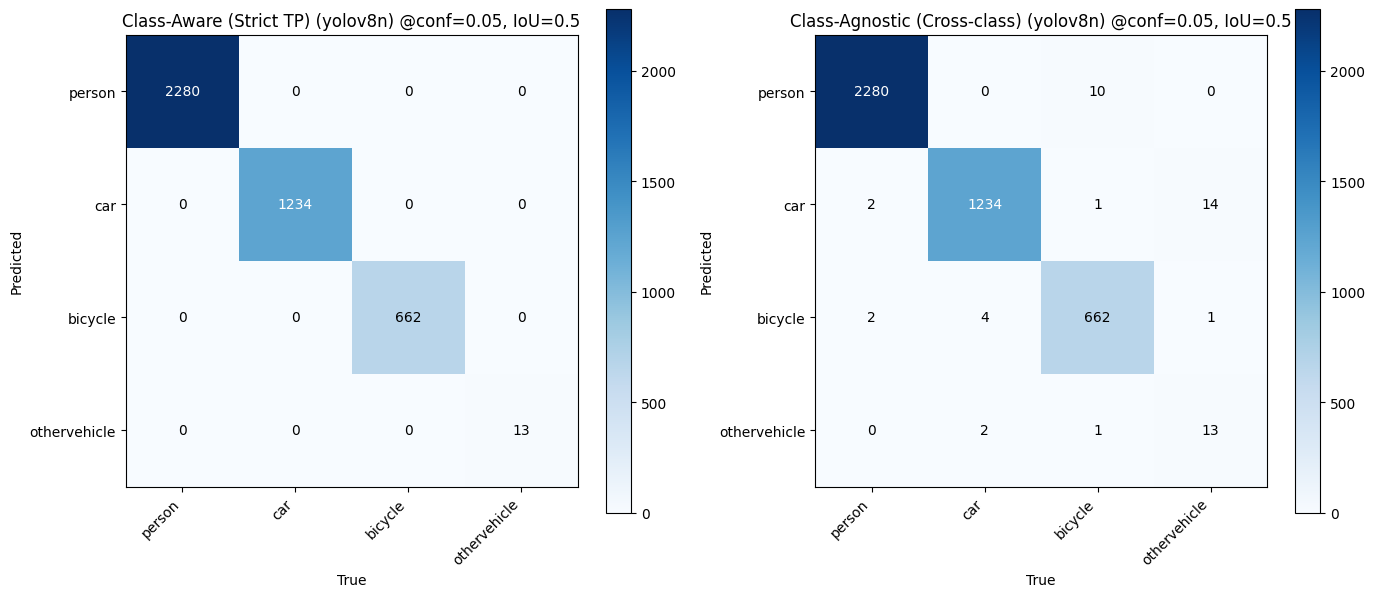


【yolov8s】CONF=0.05, IoU=0.5
背景FP（无匹配乱框）: 1791
类一致 TP=4246, FP=0, FN=0, P=1.0000, R=1.0000, F1=1.0000
类无关 TP(形状正确)=4246, 跨类误检=41

类一致矩阵（严格TP，行=预测, 列=真实）:
              person   car  bicycle  othervehicle
person          2278     0        0             0
car                0  1253        0             0
bicycle            0     0      700             0
othervehicle       0     0        0            15

类无关矩阵（跨类误检流向，行=预测, 列=真实）:
              person   car  bicycle  othervehicle
person          2278     0       10             0
car                2  1253        1            16
bicycle            3     1      700             0
othervehicle       0     6        2            15
✅ 双矩阵图已保存: /root/hit-uav/M4_dual_confusion_yolov8s.png


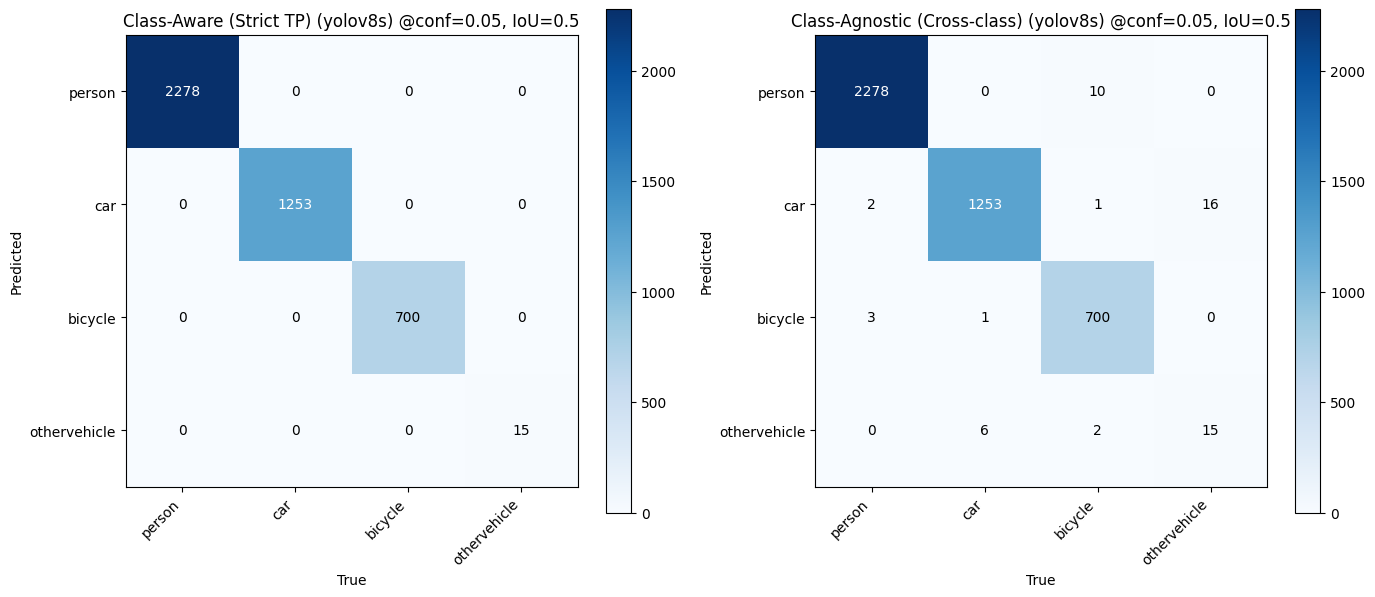


【yolov8x】CONF=0.05, IoU=0.5
背景FP（无匹配乱框）: 922
类一致 TP=4090, FP=0, FN=0, P=1.0000, R=1.0000, F1=1.0000
类无关 TP(形状正确)=4090, 跨类误检=40

类一致矩阵（严格TP，行=预测, 列=真实）:
              person   car  bicycle  othervehicle
person          2261     0        0             0
car                0  1189        0             0
bicycle            0     0      622             0
othervehicle       0     0        0            18

类无关矩阵（跨类误检流向，行=预测, 列=真实）:
              person   car  bicycle  othervehicle
person          2261     0       17             0
car                1  1189        1             8
bicycle            2     0      622             0
othervehicle       0     9        2            18
✅ 双矩阵图已保存: /root/hit-uav/M4_dual_confusion_yolov8x.png


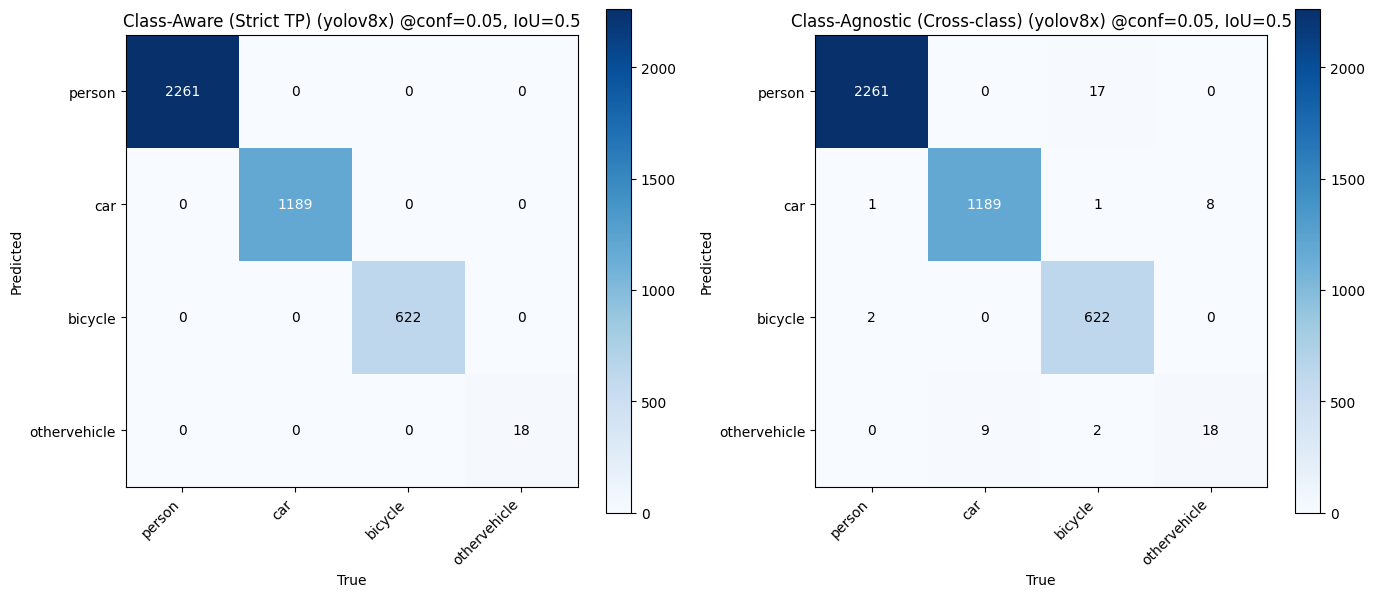


【rtdetr_r50】CONF=0.05, IoU=0.5
背景FP（无匹配乱框）: 1389
类一致 TP=4398, FP=0, FN=0, P=1.0000, R=1.0000, F1=1.0000
类无关 TP(形状正确)=4398, 跨类误检=30

类一致矩阵（严格TP，行=预测, 列=真实）:
              person   car  bicycle  othervehicle
person          2392     0        0             0
car                0  1279        0             0
bicycle            0     0      711             0
othervehicle       0     0        0            16

类无关矩阵（跨类误检流向，行=预测, 列=真实）:
              person   car  bicycle  othervehicle
person          2392     0        9             0
car                1  1279        2            11
bicycle            2     0      711             0
othervehicle       0     5        0            16
✅ 双矩阵图已保存: /root/hit-uav/M4_dual_confusion_rtdetr_r50.png


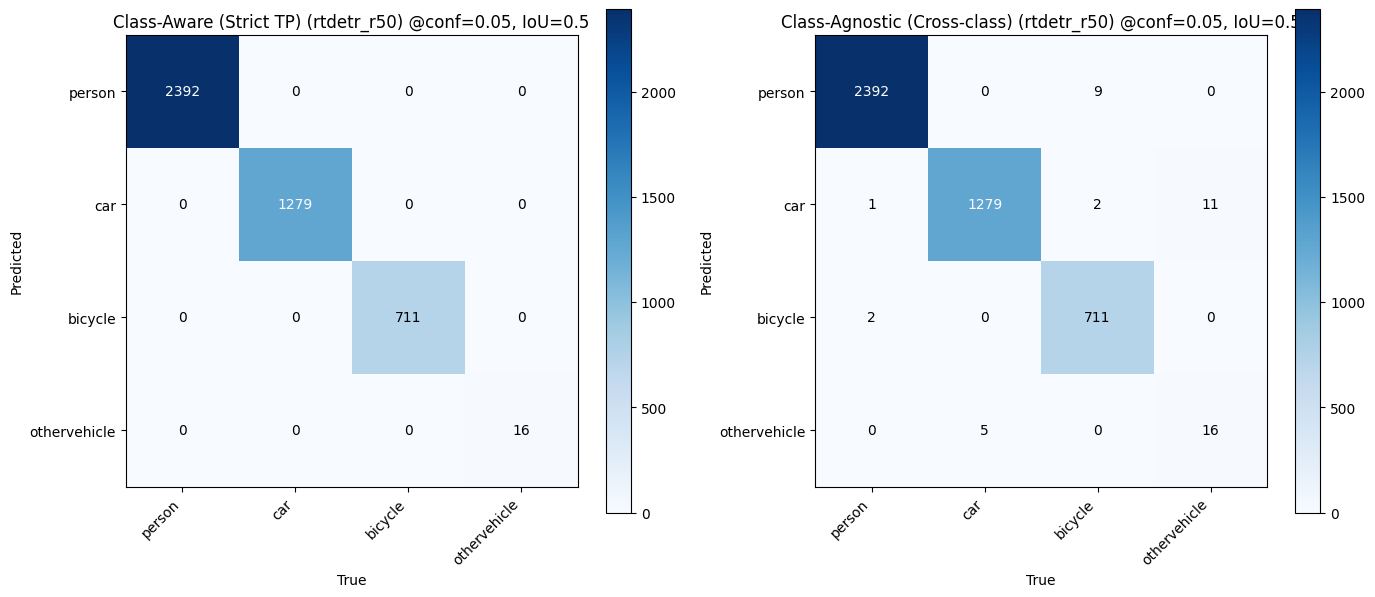



M4 类别混淆矩阵汇总表
        模型   TP  FP  FN  背景FP  跨类误检   P   R  F1
   yolov8n 4189   0   0  1322    37 1.0 1.0 1.0
   yolov8s 4246   0   0  1791    41 1.0 1.0 1.0
   yolov8x 4090   0   0   922    40 1.0 1.0 1.0
rtdetr_r50 4398   0   0  1389    30 1.0 1.0 1.0

✅ 汇总结果已保存至: /root/hit-uav/M4_confusion_summary.json


In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path('/root/hit-uav')
CLASS_NAMES = ['person', 'car', 'bicycle', 'othervehicle']
N = len(CLASS_NAMES)

MODELS = {
    'yolov8n':   ROOT / 'yolov8n_results'   / 'true_predictions' / 'yolov8n_pred.json',
    'yolov8s':   ROOT / 'yolov8s_results'   / 'true_predictions' / 'yolov8s_pred.json',
    'yolov8x':   ROOT / 'yolov8x_results'   / 'true_predictions' / 'yolov8x_pred.json',
    'rtdetr_l': ROOT / 'rtdetr_l_results' / 'true_predictions' / 'rtdetr_l_pred.json',
}

GT_LABEL_DIR = ROOT / 'labels' / 'test'
IMG_W, IMG_H = 640, 512
CONF_THRES = 0.05
IOU_THRES = 0.5

plt.rcParams['font.sans-serif'] = ['SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

# ============ 基础函数 ============
def iou(boxA, boxB):
    xA = max(boxA[1], boxB[1])
    yA = max(boxA[2], boxB[2])
    xB = min(boxA[3], boxB[3])
    yB = min(boxA[4], boxB[4])
    interW = max(0, xB - xA)
    interH = max(0, yB - yA)
    interArea = interW * interH
    boxAArea = max(0, boxA[3] - boxA[1]) * max(0, boxA[4] - boxA[2])
    boxBArea = max(0, boxB[3] - boxB[1]) * max(0, boxB[4] - boxB[2])
    denom = boxAArea + boxBArea - interArea
    return interArea / denom if denom > 0 else 0.0

def load_gt(label_dir):
    """加载 GT：YOLO 归一化 → 绝对坐标 [cls, x1, y1, x2, y2]"""
    gt_by_img = {}
    for txt in Path(label_dir).glob('*.txt'):
        img_id = txt.stem
        gts = []
        with open(txt) as f:
            for line in f.readlines():
                line = line.strip()
                if not line:
                    continue
                parts = line.split()
                if len(parts) < 5:
                    continue
                cls = int(parts[0])
                if cls >= N:
                    continue
                cx, cy, bw, bh = map(float, parts[1:5])
                x1 = (cx - bw / 2) * IMG_W
                y1 = (cy - bh / 2) * IMG_H
                x2 = (cx + bw / 2) * IMG_W
                y2 = (cy + bh / 2) * IMG_H
                gts.append([cls, x1, y1, x2, y2])
        gt_by_img[img_id] = gts
    return gt_by_img

def load_pred(json_path):
    """读取预测文件，格式 [cls, x1, y1, x2, y2, conf]"""
    with open(json_path) as f:
        data = json.load(f)
    pred_by_img = {}
    for k, v in data.items():
        img_id = str(k).strip()
        preds = []
        for d in v:
            cls = int(d[0])
            if cls >= N:
                continue
            conf = float(d[5]) if len(d) > 5 else 1.0
            preds.append([cls, float(d[1]), float(d[2]), float(d[3]), float(d[4]), conf])
        pred_by_img[img_id] = preds
    return pred_by_img

def match_iou_greedy(dets, gts, iou_thres=IOU_THRES):
    """类无关贪心匹配：按置信度降序处理，允许跨类匹配"""
    dets_sorted = sorted(dets, key=lambda x: x[5], reverse=True)
    pairs = []
    for i, d in enumerate(dets_sorted):
        for j, g in enumerate(gts):
            v = iou(d, g)
            if v > iou_thres:
                pairs.append((v, i, j))
    pairs.sort(key=lambda x: -x[0])
    used_d, used_g, matches = set(), set(), []
    for v, i, j in pairs:
        if i in used_d or j in used_g:
            continue
        used_d.add(i); used_g.add(j)
        matches.append((i, j))
    return matches, used_d

# ============ 主流程 ============
gt_by_img = load_gt(GT_LABEL_DIR)
print(f"GT 图片数: {len(gt_by_img)}")
print(f"GT 总框数: {sum(len(v) for v in gt_by_img.values())}")

summary_results = []

for model_name, json_path in MODELS.items():
    if not Path(json_path).exists():
        print(f"跳过 {model_name}: 文件不存在 {json_path}")
        continue

    pred_by_img = load_pred(json_path)

    conf_mat_agnostic = np.zeros((N, N), dtype=int)
    conf_mat_aware = np.zeros((N, N), dtype=int)
    bg_fp_count = 0

    for img_id, gts in gt_by_img.items():
        dets = [d for d in pred_by_img.get(img_id, []) if d[5] >= CONF_THRES]
        valid_gts = [g for g in gts if int(g[0]) < N]

        matches_agn, used_d_idx = match_iou_greedy(dets, valid_gts)

        for i, j in matches_agn:
            p_cls, g_cls = int(dets[i][0]), int(valid_gts[j][0])
            conf_mat_agnostic[p_cls, g_cls] += 1
            if p_cls == g_cls:
                conf_mat_aware[p_cls, g_cls] += 1

        bg_fp_count += (len(dets) - len(used_d_idx))

    # 整体指标（类一致口径）
    diag_aware = np.diag(conf_mat_aware)
    tp_aware = int(diag_aware.sum())
    pred_totals_aware = conf_mat_aware.sum(axis=1)
    gt_totals_aware = conf_mat_aware.sum(axis=0)
    fp_aware = int((pred_totals_aware - diag_aware).sum())
    fn_aware = int((gt_totals_aware - diag_aware).sum())
    precision = tp_aware / (tp_aware + fp_aware) if (tp_aware + fp_aware) > 0 else 0
    recall = tp_aware / (tp_aware + fn_aware) if (tp_aware + fn_aware) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0

    diag_agnostic = np.diag(conf_mat_agnostic)
    tp_agnostic = int(diag_agnostic.sum())
    cross_class_fp = int(conf_mat_agnostic.sum() - tp_agnostic)

    summary_results.append({
        '模型': model_name, 'TP': tp_aware, 'FP': fp_aware, 'FN': fn_aware,
        '背景FP': bg_fp_count, '跨类误检': cross_class_fp,
        'P': precision, 'R': recall, 'F1': f1
    })

    print(f"\n【{model_name}】CONF={CONF_THRES}, IoU={IOU_THRES}")
    print(f"背景FP（无匹配乱框）: {bg_fp_count}")
    print(f"类一致 TP={tp_aware}, FP={fp_aware}, FN={fn_aware}, P={precision:.4f}, R={recall:.4f}, F1={f1:.4f}")
    print(f"类无关 TP(形状正确)={tp_agnostic}, 跨类误检={cross_class_fp}")

    print("\n类一致矩阵（严格TP，行=预测, 列=真实）:")
    print(pd.DataFrame(conf_mat_aware, index=CLASS_NAMES, columns=CLASS_NAMES))

    print("\n类无关矩阵（跨类误检流向，行=预测, 列=真实）:")
    print(pd.DataFrame(conf_mat_agnostic, index=CLASS_NAMES, columns=CLASS_NAMES))

    # ============ 绘制双矩阵（下侧标签45°倾斜） ============
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    for ax, mat, title in zip(axes, [conf_mat_aware, conf_mat_agnostic],
                              ['Class-Aware (Strict TP)', 'Class-Agnostic (Cross-class)']):
        im = ax.imshow(mat, cmap='Blues')
        ax.set_xticks(range(N))
        ax.set_xticklabels(CLASS_NAMES, rotation=45, ha='right', fontsize=10)
        ax.set_yticks(range(N))
        ax.set_yticklabels(CLASS_NAMES, fontsize=10)
        ax.set_xlabel('True')
        ax.set_ylabel('Predicted')
        ax.set_title(f'{title} ({model_name}) @conf={CONF_THRES}, IoU={IOU_THRES}')
        max_val = mat.max() if mat.max() > 0 else 1
        for i in range(N):
            for j in range(N):
                v = mat[i, j]
                ax.text(j, i, str(v), ha='center', va='center',
                        color='white' if v > max_val / 2 else 'black', fontsize=10)
        fig.colorbar(im, ax=ax)
    plt.tight_layout()

    save_p = ROOT / f'M4_dual_confusion_{model_name}.png'
    plt.savefig(save_p, dpi=200, bbox_inches='tight')
    print(f"✅ 双矩阵图已保存: {save_p}")
    plt.show()

# ============ 打印汇总表 ============
print("\n\n" + "=" * 100)
print("M4 类别混淆矩阵汇总表")
print("=" * 100)
df_summary = pd.DataFrame(summary_results)
print(df_summary.to_string(index=False))

save_json = ROOT / 'M4_confusion_summary.json'
df_summary.to_json(save_json, orient='records', indent=2, force_ascii=False)
print(f"\n✅ 汇总结果已保存至: {save_json}")

✅ /root/hit-uav/evaluate_results/PR_curve_overall.png


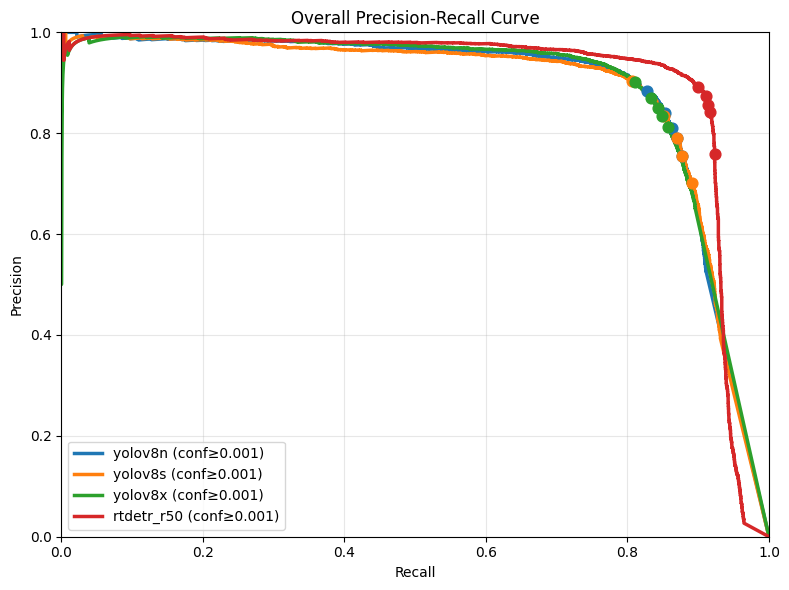

✅ /root/hit-uav/evaluate_results/M5_PR_curve_per_class.png


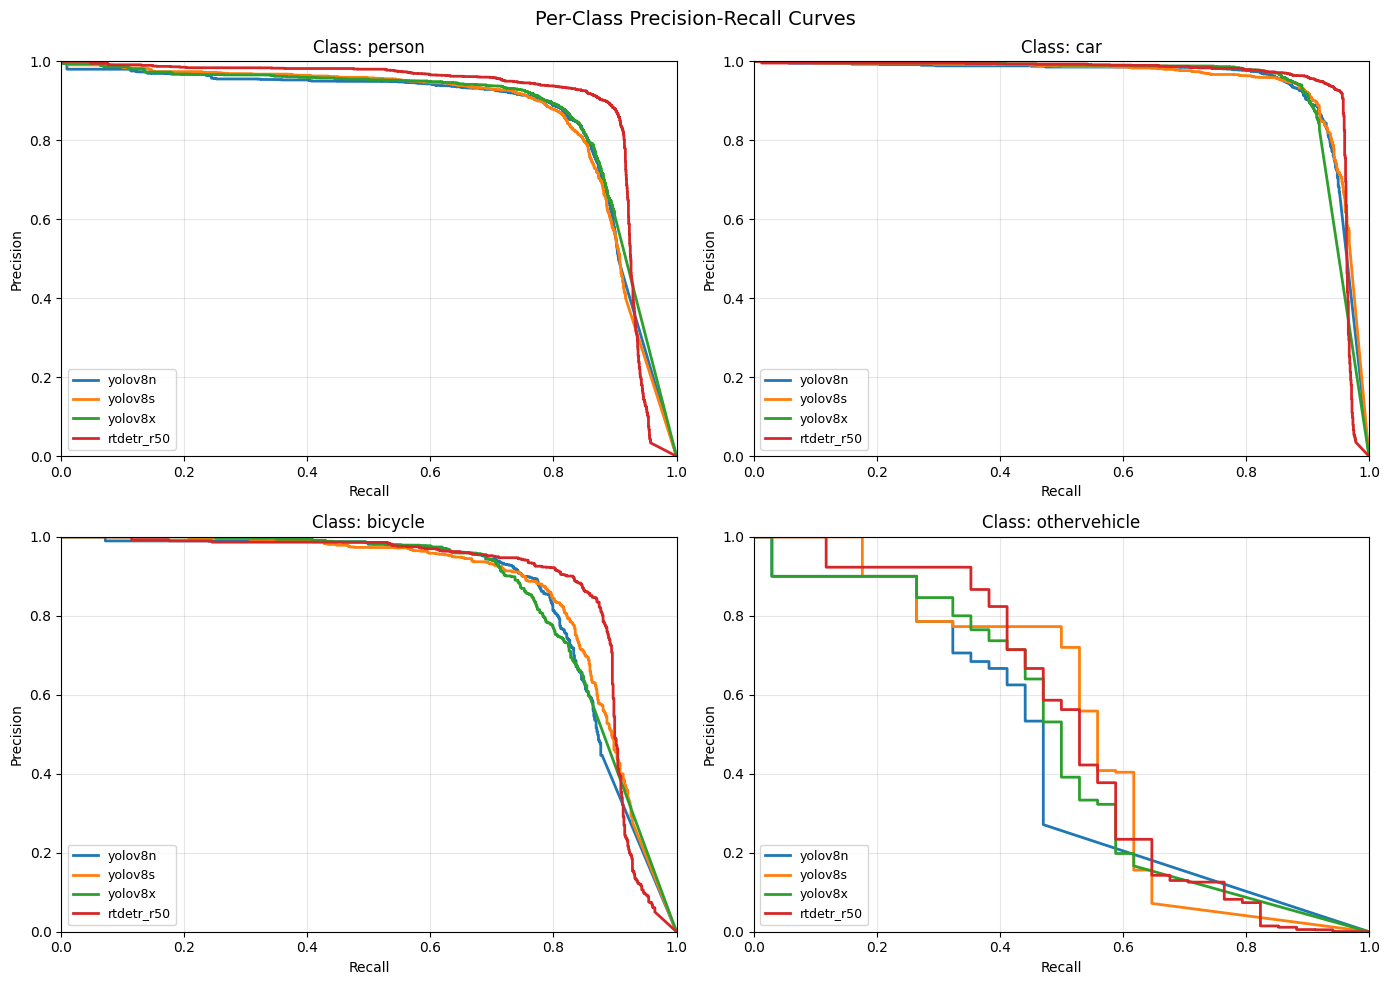

In [3]:
import json
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path('/root/hit-uav')
CLASS_NAMES = ['person', 'car', 'bicycle', 'othervehicle']
NUM_CLASSES = len(CLASS_NAMES)

# 注意：根据你 M1 代码实际保存位置修改
M1_PATH = ROOT / 'evaluate_results' / 'M1_summary.json'
M2_PATH = ROOT / 'evaluate_results' / 'M2_conf_sensitivity.json'

colors = {'yolov8n': 'C0', 'yolov8s': 'C1', 'yolov8x': 'C2', 'rtdetr_l': 'C3'}
valid_models = ['yolov8n', 'yolov8s', 'yolov8x', 'rtdetr_l']

plt.rcParams['font.sans-serif'] = ['SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

# ---------- 读取 M1 ----------
with open(M1_PATH) as f:
    m1_data = json.load(f)

# 兼容两种格式：
# 1) 新格式：{"ap": {...}, "prf": {...}}
# 2) 旧格式：直接是 {model: {...}}
if 'ap' in m1_data:
    model_data = m1_data['ap']
else:
    model_data = m1_data

# 只保留有效模型，且必须有 pr_curves
model_data = {
    name: d for name, d in model_data.items()
    if name in valid_models and 'pr_curves' in d
}
models = list(model_data.keys())

# ---------- 读取 M2（可选） ----------
m2_data = {}
if M2_PATH.exists():
    with open(M2_PATH) as f:
        m2_data = json.load(f)

# ---------- 图一：整体 PR 曲线 + M2 采样点 ----------
fig, ax = plt.subplots(figsize=(8, 6))

for model in models:
    d = model_data[model]
    overall = d['pr_curves']['overall']
    ax.plot(overall['rc'], overall['pr'],
            linestyle='-', linewidth=2.5,
            color=colors.get(model, 'gray'),
            label=f'{model} (conf≥0.001)')

    # 叠加 M2 五点采样
    if model in m2_data:
        try:
            confs = sorted(m2_data[model].keys(), key=lambda x: float(x))
            p_list = []
            r_list = []
            for c in confs:
                item = m2_data[model][c]
                p_list.append(float(item['Precision']))
                r_list.append(float(item['Recall']))
            ax.scatter(r_list, p_list, marker='o', s=60,
                       color=colors.get(model, 'gray'), zorder=5)
        except Exception as e:
            print(f"{model} M2 数据格式异常: {e}")

ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Overall Precision-Recall Curve')
ax.grid(True, alpha=0.3)
ax.legend(loc='lower left')
ax.set_xlim([0, 1])
ax.set_ylim([0, 1])

plt.tight_layout()
p1 = ROOT / 'evaluate_results' / 'PR_curve_overall.png'
plt.savefig(p1, dpi=200, bbox_inches='tight')
print(f"✅ {p1}")
plt.show()

# ---------- 图二：各类别 PR 曲线 ----------
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for c, cls_name in enumerate(CLASS_NAMES):
    ax = axes[c]
    for model in models:
        d = model_data[model]
        per_class = d['pr_curves']['per_class']

        # 兼容列表或字典格式
        if isinstance(per_class, dict):
            cls_data = per_class.get(cls_name, {})
        else:
            cls_data = per_class[c] if c < len(per_class) else {}

        if 'rc' not in cls_data or 'pr' not in cls_data:
            continue

        ax.plot(cls_data['rc'], cls_data['pr'],
                linestyle='-', linewidth=2,
                color=colors.get(model, 'gray'),
                label=model)

    ax.set_xlabel('Recall')
    ax.set_ylabel('Precision')
    ax.set_title(f'Class: {cls_name}')
    ax.grid(True, alpha=0.3)
    ax.legend(loc='lower left', fontsize=9)
    ax.set_xlim([0, 1])
    ax.set_ylim([0, 1])

plt.suptitle('Per-Class Precision-Recall Curves', fontsize=14)
plt.tight_layout()
p2 = ROOT /  'evaluate_results' /'M5_PR_curve_per_class.png'
plt.savefig(p2, dpi=200, bbox_inches='tight')
print(f"✅ {p2}")
plt.show()

【警告】rtdetr_r50 找不到 box_loss 列，请检查 CSV 表头！


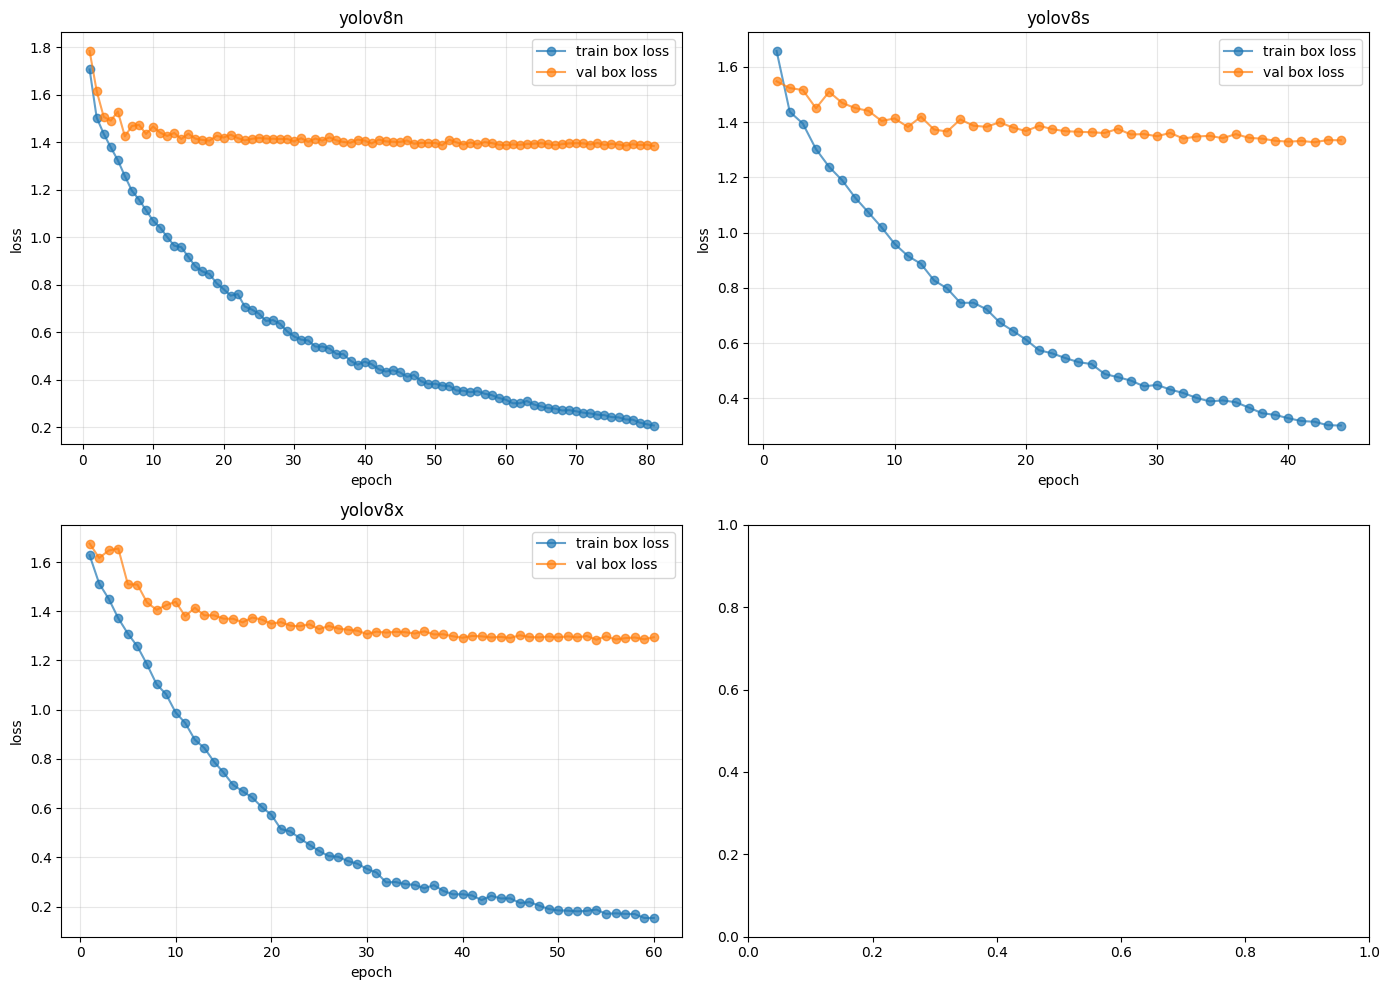

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path('/root/hit-uav')

model_dirs = {
    'yolov8n':    ROOT / 'yolov8n_results'    / 'yolov8n_finetune',
    'yolov8s':    ROOT / 'yolov8s_results'    / 'yolov8s_finetune',
    'yolov8x':    ROOT / 'yolov8x_results'    / 'yolov8x_finetune',
    'rtdetr_l': ROOT / 'rtdetr_l_results' / 'rtdetr_l_finetune',
}

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for idx, (name, dir_path) in enumerate(model_dirs.items()):
    csv_path = dir_path / 'results.csv'
    
    if not csv_path.exists():
        print(f'{name}: 未找到 {csv_path}')
        continue
        
    df = pd.read_csv(csv_path)
    df.columns = df.columns.str.strip()
    
    # 调试打印
    # print(f"{name} 列名:", df.columns.tolist())

    # 模糊匹配列名（兼容带 (B) 后缀或版本差异）
    train_loss_col = [c for c in df.columns if 'train' in c and 'box_loss' in c]
    val_loss_col = [c for c in df.columns if 'val' in c and 'box_loss' in c]
    
    if not train_loss_col or not val_loss_col:
        print(f"【警告】{name} 找不到 box_loss 列，请检查 CSV 表头！")
        continue
        
    train_loss_col = train_loss_col[0]
    val_loss_col = val_loss_col[0]

    ax = axes[idx]
    ax.plot(df['epoch'], df[train_loss_col], 'o-', label='train box loss', alpha=0.7)
    ax.plot(df['epoch'], df[val_loss_col],   'o-', label='val box loss',   alpha=0.7)
    ax.set_title(name)
    ax.set_xlabel('epoch')
    ax.set_ylabel('loss')
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()